# SubsetsC2: KNN vs diffusion as a function of dataset size

**Question.** How much data does KNN retrieval need to match one diffusion counterfactual,
and how much does averaging K neighbours lower that?

**Setup** (`code/c2_knn_size_sweep.py`, model `MLP_I+C+D`, no prob):
- **Test**: the 5 test folds of the 20k diffusion subset (~20k rows), the same for every arm, N, K and seed.
- **Train**: N rows drawn per fold as nested, patient-whole subsamples, 5 seeds.
  - KNN: drawn from all of `c2_data` minus the test-fold patients. The N rows are also the only rows KNN can retrieve from.
  - Diffusion: drawn from the 4 diffusion train folds (max ~16k). One generated CF per query (K=1, `high` level).
- **Score**: AUROC pooled over the 5 test folds, then mean ± SD over seeds.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

sys.path.insert(0, os.path.abspath("code"))
from thesis_style import *
apply()

RESULTS  = os.environ.get("THESIS_RESULTS", "/work3/s251710/thesis_results")
C2       = os.path.join(RESULTS, "C2_final_results")
FIG_DIR  = os.path.join("figures", "c2")
DISEASES = ["effusion", "edema", "atelectasis", "cardiomegaly", "consolidation"]
CONFIG   = "I+C+D"
KS_PLOT  = [1, 5, 20]          # KNN K values drawn in the figure
KS_TABLE = [1, 3, 5, 10, 20]
os.makedirs(FIG_DIR, exist_ok=True)

## Load

In [2]:
def load(disease):
    p = os.path.join(C2, disease, "knn_size_sweep", "sweep_pooled.csv")
    r = pd.read_csv(p)
    r = r[r["config"] == CONFIG].copy()
    r["disease"] = disease
    return r

raw = pd.concat([load(d) for d in DISEASES], ignore_index=True)

# One row per (disease, arm, N, K): mean and SD over seeds. x-axis = the actual mean
# number of training rows (subsamples are patient-whole, so slightly above the target).
agg = (raw.groupby(["disease", "arm", "n_target", "k"])
          .agg(auc=("auc", "mean"), sd=("auc", "std"), n_seeds=("seed", "nunique"),
               n_train=("n_train_mean", "mean"), msp=("msp_auc", "first"))
          .reset_index()
          .sort_values(["disease", "arm", "n_train", "k"]))
MSP = agg.groupby("disease")["msp"].first()
agg.head()

,disease,arm,n_target,k,auc,sd,n_seeds,n_train,msp
0,atelectasis,diffusion,1000,1,0.832923,0.003113,5,1000.92,0.864664
1,atelectasis,diffusion,2000,1,0.835788,0.006311,5,2000.28,0.864664
3,atelectasis,diffusion,4000,1,0.844866,0.001493,5,4000.68,0.864664
4,atelectasis,diffusion,8000,1,0.850610,0.002559,5,8000.80,0.864664
2,atelectasis,diffusion,20k,1,0.854056,0.001191,5,16000.00,0.864664


## AUROC by N

In [3]:
def wide(disease):
    a = agg[agg["disease"] == disease]
    knn = a[a["arm"] == "knn"].pivot_table(index="n_train", columns="k", values="auc")
    knn = knn[[k for k in KS_TABLE if k in knn]].add_prefix("KNN K")
    dif = a[a["arm"] == "diffusion"].set_index("n_train")["auc"].rename("Diffusion K1")
    t = pd.concat([dif, knn], axis=1).sort_index()
    t.index = [f"{n/1000:.1f}k" for n in t.index]
    t.index.name = "N"
    return t

for d in DISEASES:
    print(f"\n{d}   (MSP = {MSP[d]:.4f})")
    display(wide(d).round(4))


effusion   (MSP = 0.7824)


,Diffusion K1,KNN K1,KNN K3,KNN K5,KNN K10,KNN K20
N,,,,,,
1.0k,0.6951,NaN,NaN,NaN,NaN,NaN
1.0k,NaN,0.6819,0.6981,0.7030,0.7067,0.7094
2.0k,0.7251,NaN,NaN,NaN,NaN,NaN
2.0k,NaN,0.6981,0.7137,0.7182,0.7213,0.7224
4.0k,0.7445,NaN,NaN,NaN,NaN,NaN
4.0k,NaN,0.7295,0.7428,0.7458,0.7482,0.7487
8.0k,0.7604,NaN,NaN,NaN,NaN,NaN
8.0k,NaN,0.7483,0.7565,0.7586,0.7603,0.7611
16.0k,0.7708,NaN,NaN,NaN,NaN,NaN



edema   (MSP = 0.8309)


,Diffusion K1,KNN K1,KNN K3,KNN K5,KNN K10,KNN K20
N,,,,,,
1.0k,0.7725,NaN,NaN,NaN,NaN,NaN
1.0k,NaN,0.7423,0.7606,0.7654,0.7691,0.7714
2.0k,0.7969,NaN,NaN,NaN,NaN,NaN
2.0k,NaN,0.7692,0.7817,0.7850,0.7872,0.7883
4.0k,0.8104,NaN,NaN,NaN,NaN,NaN
4.0k,NaN,0.7749,0.7888,0.7921,0.7948,0.7963
8.0k,0.8190,NaN,NaN,NaN,NaN,NaN
8.0k,NaN,0.8027,0.8126,0.8146,0.8159,0.8168
16.0k,0.8244,NaN,NaN,NaN,NaN,NaN



atelectasis   (MSP = 0.8647)


,Diffusion K1,KNN K1,KNN K3,KNN K5,KNN K10,KNN K20
N,,,,,,
1.0k,0.8329,NaN,NaN,NaN,NaN,NaN
1.0k,NaN,0.8070,0.8223,0.8249,0.8267,0.8271
2.0k,0.8358,NaN,NaN,NaN,NaN,NaN
2.0k,NaN,0.8204,0.8305,0.8324,0.8329,0.8334
4.0k,0.8449,NaN,NaN,NaN,NaN,NaN
4.0k,NaN,0.8333,0.8395,0.8407,0.8410,0.8411
8.0k,0.8506,NaN,NaN,NaN,NaN,NaN
8.0k,NaN,0.8405,0.8471,0.8480,0.8485,0.8486
16.0k,0.8541,NaN,NaN,NaN,NaN,NaN



cardiomegaly   (MSP = 0.9145)


,Diffusion K1,KNN K1,KNN K3,KNN K5,KNN K10,KNN K20
N,,,,,,
1.0k,0.8711,NaN,NaN,NaN,NaN,NaN
1.0k,NaN,0.8444,0.8602,0.8626,0.8643,0.8650
2.0k,0.8876,NaN,NaN,NaN,NaN,NaN
2.0k,NaN,0.8684,0.8792,0.8814,0.8830,0.8836
4.0k,0.8962,NaN,NaN,NaN,NaN,NaN
4.0k,NaN,0.8809,0.8900,0.8918,0.8934,0.8944
8.0k,0.9059,NaN,NaN,NaN,NaN,NaN
8.0k,NaN,0.8960,0.9030,0.9043,0.9052,0.9056
16.0k,0.9101,NaN,NaN,NaN,NaN,NaN



consolidation   (MSP = 0.9475)


,Diffusion K1,KNN K1,KNN K3,KNN K5,KNN K10,KNN K20
N,,,,,,
1.0k,0.9293,NaN,NaN,NaN,NaN,NaN
1.0k,NaN,0.9146,0.9249,0.9267,0.9277,0.9281
2.0k,0.9299,NaN,NaN,NaN,NaN,NaN
2.0k,NaN,0.9235,0.9292,0.9298,0.9302,0.9305
4.0k,0.9362,NaN,NaN,NaN,NaN,NaN
4.0k,NaN,0.9269,0.9312,0.9319,0.9322,0.9325
8.0k,0.9379,NaN,NaN,NaN,NaN,NaN
8.0k,NaN,0.9300,0.9341,0.9345,0.9350,0.9354
16.0k,0.9410,NaN,NaN,NaN,NaN,NaN


## Figure: AUROC vs N

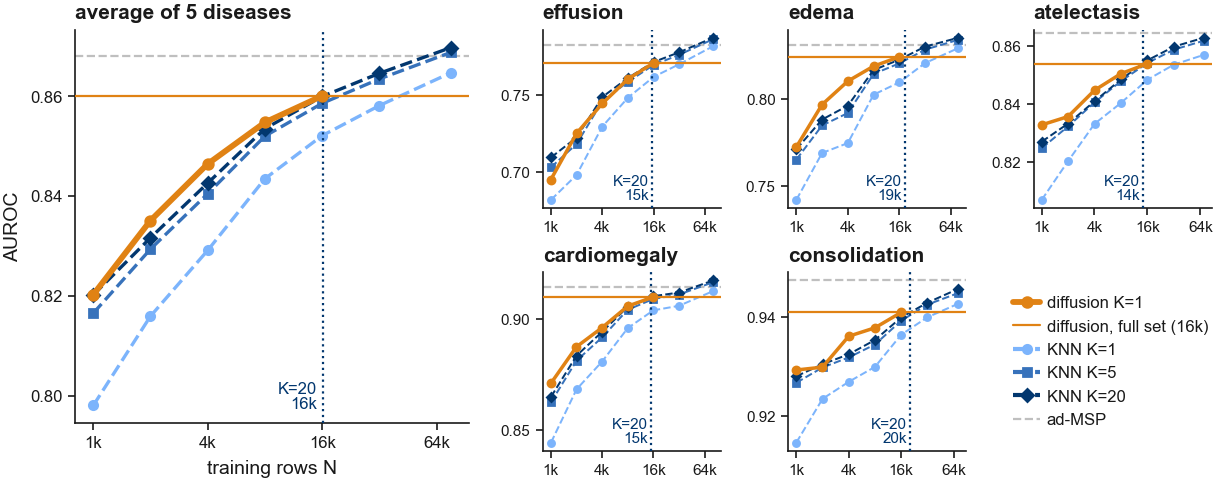

In [4]:
from matplotlib.ticker import MaxNLocator

DIFF_COLOR = "#E08214"
SHOW_DIFF_CURVE = True    # diffusion AUROC vs N; False = only its full-set level as a horizontal line
knn_colors, knn_markers = k_colors("attr", KS_PLOT), k_markers(KS_PLOT)

# Key panel = the average over diseases: AUROC and N averaged per (arm, N, K). Every disease
# runs the same N grid, so the points line up (KNN "all" differs, 70-80k, and is averaged too).
curves = {d: agg[agg["disease"] == d] for d in DISEASES}
curves["AVERAGE"] = (agg.groupby(["arm", "n_target", "k"])
                        .agg(auc=("auc", "mean"), n_train=("n_train", "mean"))
                        .reset_index().sort_values(["arm", "n_train", "k"]))
msp = {**MSP.to_dict(), "AVERAGE": MSP[DISEASES].mean()}


def auroc_vs_n_draw(ax, d, compact):
    """draw(ax, panel, compact) for key_figure: compact = a small disease panel."""
    a  = curves[d]
    ms = 2.2 if compact else 3
    lw = 0.6 if compact else 1
    for k in KS_PLOT:
        s = a[(a["arm"] == "knn") & (a["k"] == k)].sort_values("n_train")
        ax.plot(s["n_train"], s["auc"], ls="--", color=knn_colors[k],
                marker=knn_markers[k], ms=ms, lw=LW["line"] * 0.8 * lw)
    s = a[(a["arm"] == "diffusion") & (a["k"] == 1)].sort_values("n_train")
    if SHOW_DIFF_CURVE:
        ax.plot(s["n_train"], s["auc"], ls="-", color=DIFF_COLOR, marker="o", ms=ms * 1.15,
                lw=LW["line"] * 1.4 * lw, zorder=5)
    msp_line(ax, msp[d])

    # Diffusion on its full train side (~16k): the level KNN has to cross.
    target = s["auc"].iloc[-1]
    ax.axhline(target, ls="-", color=DIFF_COLOR, lw=LW["ref"], zorder=4)

    # First N at which a KNN curve reaches it, interpolated in log N between grid points.
    crossings = {}
    for k in KS_PLOT:
        sk = a[(a["arm"] == "knn") & (a["k"] == k)].sort_values("n_train")
        x, y = np.log(sk["n_train"].values), sk["auc"].values
        up = np.where((y[:-1] < target) & (y[1:] >= target))[0]
        if y[0] >= target:
            crossings[k] = sk["n_train"].iloc[0]
        elif len(up):
            i = up[0]
            crossings[k] = np.exp(x[i] + (target - y[i]) / (y[i + 1] - y[i]) * (x[i + 1] - x[i]))
    if crossings:
        k_first = min(crossings, key=crossings.get)
        ax.axvline(crossings[k_first], ls=":", color=knn_colors[k_first], lw=LW["ref"], zorder=4)
        ax.text(crossings[k_first] * 0.92, 0.03, f"K={k_first}\n{crossings[k_first] / 1000:.0f}k",
                transform=ax.get_xaxis_transform(), ha="right", va="bottom",
                fontsize=FS["tiny"] if compact else FS["small"], color=knn_colors[k_first],
                linespacing=1.0)

    ax.set_xscale("log")
    ax.set_xticks([1e3, 4e3, 16e3, 64e3])
    ax.minorticks_off()
    ax.set_xticklabels(["1k", "4k", "16k", "64k"])
    ax.yaxis.set_major_locator(MaxNLocator(nbins=3 if compact else 5, steps=[1, 2, 5, 10]))
    if compact:
        ax.tick_params(labelsize=FS["tiny"])
    else:
        ax.set_xlabel("training rows N")
    ax.set_title(f"average of {len(DISEASES)} diseases" if d == "AVERAGE" else d)


handles = ([Line2D([], [], color=DIFF_COLOR, marker="o", ms=3.5, lw=LW["line"] * 1.4,
                   label="diffusion K=1")] if SHOW_DIFF_CURVE else []) \
          + [Line2D([], [], color=DIFF_COLOR, lw=LW["ref"], label="diffusion, full set (16k)")] \
          + [Line2D([], [], color=knn_colors[k], ls="--", marker=knn_markers[k], ms=3,
                    label=f"KNN K={k}") for k in KS_PLOT] \
          + [msp_handle("ad-MSP")]
fig = key_figure(DISEASES + ["AVERAGE"], auroc_vs_n_draw, handles, ylabel="AUROC")
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIG_DIR, f"subsets_c2_auroc_vs_n.{ext}"))
# Key-figure folder, as in C2_evaluation: same name, PDF only.
KEY_FIG_DIR = os.path.join("figures", "c2_key")
os.makedirs(KEY_FIG_DIR, exist_ok=True)
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(KEY_FIG_DIR, f"subsets_c2_auroc_vs_n.{ext}"))
plt.show()

## Diffusion minus KNN at equal N

Positive = diffusion better. Only N values both arms were run at (≤ ~16k).

In [5]:
def gap(disease):
    a = agg[agg["disease"] == disease]
    dif = a[a["arm"] == "diffusion"].set_index("n_target")["auc"]
    knn = a[a["arm"] == "knn"].pivot_table(index="n_target", columns="k", values="auc")
    dif = dif.rename({"20k": "16000"})          # the full diffusion train side
    common = [n for n in dif.index if n in knn.index]
    g = knn.loc[common, [k for k in KS_TABLE if k in knn]].rsub(dif.loc[common], axis=0)
    g = g.add_prefix("K").loc[sorted(common, key=int)]
    g.index = [f"{int(n)/1000:.0f}k" for n in g.index]
    g.index.name = "N"
    return g

for d in DISEASES:
    print(f"\n{d}")
    display(gap(d).round(4))


effusion


k,K1,K3,K5,K10,K20
N,,,,,
1k,0.0132,-0.0030,-0.0079,-0.0116,-0.0143
2k,0.0270,0.0114,0.0069,0.0037,0.0027
4k,0.0149,0.0016,-0.0014,-0.0037,-0.0042
8k,0.0121,0.0039,0.0018,0.0001,-0.0007
16k,0.0090,0.0024,0.0013,0.0000,-0.0006



edema


k,K1,K3,K5,K10,K20
N,,,,,
1k,0.0303,0.0120,0.0071,0.0034,0.0012
2k,0.0277,0.0152,0.0119,0.0097,0.0086
4k,0.0355,0.0216,0.0183,0.0156,0.0141
8k,0.0163,0.0064,0.0044,0.0031,0.0022
16k,0.0146,0.0057,0.0037,0.0022,0.0016



atelectasis


k,K1,K3,K5,K10,K20
N,,,,,
1k,0.0259,0.0106,0.0080,0.0062,0.0058
2k,0.0154,0.0053,0.0034,0.0029,0.0024
4k,0.0116,0.0054,0.0042,0.0039,0.0038
8k,0.0101,0.0036,0.0026,0.0021,0.0020
16k,0.0056,0.0006,-0.0002,-0.0008,-0.0012



cardiomegaly


k,K1,K3,K5,K10,K20
N,,,,,
1k,0.0267,0.0110,0.0085,0.0068,0.0061
2k,0.0191,0.0084,0.0062,0.0046,0.0040
4k,0.0153,0.0062,0.0044,0.0028,0.0019
8k,0.0099,0.0029,0.0016,0.0007,0.0003
16k,0.0060,0.0018,0.0009,0.0000,-0.0004



consolidation


k,K1,K3,K5,K10,K20
N,,,,,
1k,0.0147,0.0044,0.0026,0.0016,0.0013
2k,0.0064,0.0007,0.0001,-0.0003,-0.0006
4k,0.0093,0.0049,0.0043,0.0040,0.0037
8k,0.0079,0.0038,0.0034,0.0028,0.0025
16k,0.0045,0.0021,0.0017,0.0012,0.0010


## Figure: diffusion minus KNN vs N

Gap = AUROC(diffusion K=1) − AUROC(KNN at K), computed per seed and then mean ± SD over seeds.
Above zero = diffusion better. The last panel averages the gap over the five diseases.

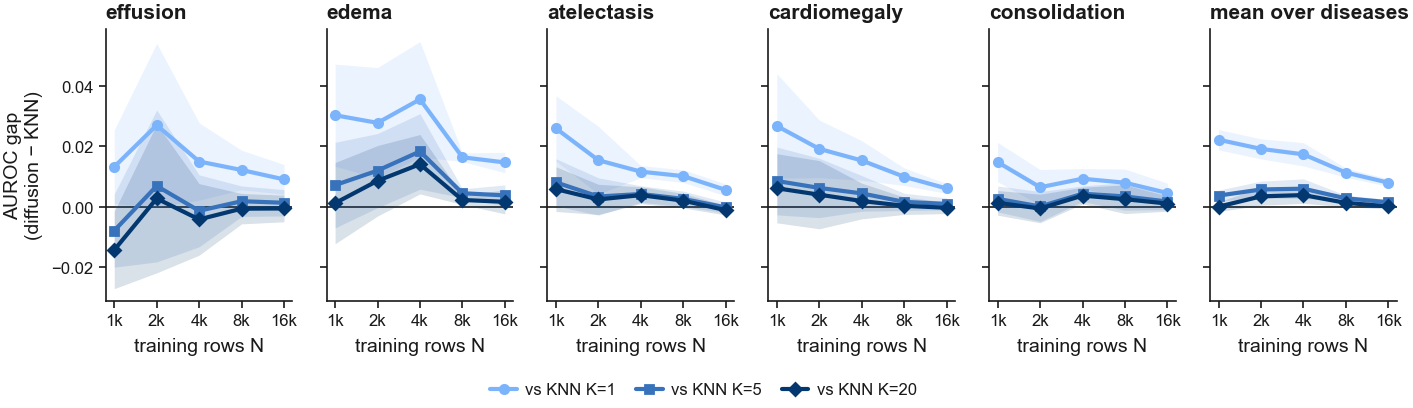

In [6]:
GAP_KS = [1, 5, 20]
gap_colors, gap_markers = k_colors("attr", GAP_KS), k_markers(GAP_KS)

r = raw.assign(n=raw["n_target"].replace({"20k": "16000"}))   # full diffusion train side = 16k
dif = r[r["arm"] == "diffusion"].pivot_table(index=["disease", "n"], columns="seed", values="auc")

gaps = []   # one row per (disease, N, K, seed)
for k in GAP_KS:
    knn = r[(r["arm"] == "knn") & (r["k"] == k)].pivot_table(
        index=["disease", "n"], columns="seed", values="auc")
    g = (dif - knn.reindex(dif.index)).stack().rename("gap").reset_index()
    g["k"] = k
    gaps.append(g)
gaps = pd.concat(gaps, ignore_index=True).dropna()
gaps["n"] = gaps["n"].astype(int)

panels = DISEASES + ["mean over diseases"]
fig, axes = plt.subplots(1, len(panels), figsize=(FULL, 50 * MM), sharex=True, sharey=True)
for ax, d in zip(axes, panels):
    g = gaps if d == panels[-1] else gaps[gaps["disease"] == d]
    if d == panels[-1]:
        # average over diseases within each seed first, so the SD is still across seeds
        g = g.groupby(["n", "k", "seed"])["gap"].mean().reset_index()
    s = g.groupby(["k", "n"])["gap"].agg(["mean", "std"]).reset_index()
    ax.axhline(0, color=INK, lw=LW["axis"], zorder=1)
    for k in GAP_KS:
        sk = s[s["k"] == k].sort_values("n")
        ax.fill_between(sk["n"], sk["mean"] - sk["std"], sk["mean"] + sk["std"],
                        color=gap_colors[k], alpha=0.15, lw=0)
        ax.plot(sk["n"], sk["mean"], color=gap_colors[k], marker=gap_markers[k], ms=3)
    ax.set_xscale("log")
    ax.set_xticks([1e3, 2e3, 4e3, 8e3, 16e3])
    ax.set_xticklabels(["1k", "2k", "4k", "8k", "16k"])
    ax.minorticks_off()
    ax.set_title(d)
    ax.set_xlabel("training rows N")
axes[0].set_ylabel("AUROC gap\n(diffusion − KNN)")

handles = [Line2D([], [], color=gap_colors[k], marker=gap_markers[k], ms=3,
                  label=f"vs KNN K={k}") for k in GAP_KS]
fig.legend(handles=handles, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.08))
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIG_DIR, f"subsets_c2_gap_vs_n.{ext}"))
plt.show()

## How much data KNN needs to match full diffusion

Smallest N at which KNN (mean over seeds) reaches diffusion K=1 trained on the full ~16k.
`>all` means it never got there within the pool.

In [7]:
rows = []
for d in DISEASES:
    a = agg[agg["disease"] == d]
    target = a[(a["arm"] == "diffusion") & (a["n_target"] == "20k")]["auc"].iloc[0]
    row = {"disease": d, "diffusion@16k": round(target, 4)}
    for k in KS_TABLE:
        s = a[(a["arm"] == "knn") & (a["k"] == k)].sort_values("n_train")
        hit = s[s["auc"] >= target]
        row[f"K{k}"] = f"{hit['n_train'].iloc[0]/1000:.0f}k" if len(hit) else ">all"
    rows.append(row)
pd.DataFrame(rows).set_index("disease")

,diffusion@16k,K1,K3,K5,K10,K20
disease,,,,,,
effusion,0.7708,79k,32k,32k,32k,16k
edema,0.8244,78k,32k,32k,32k,32k
atelectasis,0.8541,70k,32k,16k,16k,16k
cardiomegaly,0.9101,80k,32k,32k,32k,16k
consolidation,0.9410,73k,32k,32k,32k,32k


In [8]:
nstar = pd.DataFrame(rows).set_index("disease")
k_cols = [f"K{k}" for k in KS_TABLE]

def tex_n(v):
    return r"$>$all" if v == ">all" else v

lines = [
    r"\begin{table}[htbp]", r"\centering", r"\small",
    r"\caption{Training rows KNN needs to match one diffusion counterfactual. "
    r"Smallest $N$ at which the KNN attribute model (\texttt{I+C+D}, mean over 5 seeds) "
    r"reaches the AUROC of the diffusion model ($K=1$) trained on the full 16k train side. "
    r"AUROC is computed out-of-fold over the 20k diffusion subset (5-fold CV: each image is "
    r"tested once, by the model whose fold held it out), with identical folds for every cell.}",
    r"\label{tab:subsets_knn_nstar}",
    r"\begin{tabular}{l c " + "c" * len(k_cols) + "}",
    r"\toprule",
    r" & & \multicolumn{" + str(len(k_cols)) + r"}{c}{KNN $N^*$ at $K =$} \\",
    r"\cmidrule(lr){3-" + str(2 + len(k_cols)) + "}",
    r"Disease & Diffusion AUROC & " + " & ".join(str(k) for k in KS_TABLE) + r" \\",
    r"\midrule",
]
for d, r_ in nstar.iterrows():
    lines.append(f"{d.capitalize()} & {r_['diffusion@16k']:.3f} & "
                 + " & ".join(tex_n(r_[c]) for c in k_cols) + r" \\")
lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
print("\n".join(lines))

\begin{table}[htbp]
\centering
\small
\caption{Training rows KNN needs to match one diffusion counterfactual. Smallest $N$ at which the KNN attribute model (\texttt{I+C+D}, mean over 5 seeds) reaches the AUROC of the diffusion model ($K=1$) trained on the full 16k train side. AUROC is computed out-of-fold over the 20k diffusion subset (5-fold CV: each image is tested once, by the model whose fold held it out), with identical folds for every cell.}
\label{tab:subsets_knn_nstar}
\begin{tabular}{l c ccccc}
\toprule
 & & \multicolumn{5}{c}{KNN $N^*$ at $K =$} \\
\cmidrule(lr){3-7}
Disease & Diffusion AUROC & 1 & 3 & 5 & 10 & 20 \\
\midrule
Effusion & 0.771 & 79k & 32k & 32k & 32k & 16k \\
Edema & 0.824 & 78k & 32k & 32k & 32k & 32k \\
Atelectasis & 0.854 & 70k & 32k & 16k & 16k & 16k \\
Cardiomegaly & 0.910 & 80k & 32k & 32k & 32k & 16k \\
Consolidation & 0.941 & 73k & 32k & 32k & 32k & 32k \\
\bottomrule
\end{tabular}
\end{table}
